## This notebook studies food production a dn security in Rwanda using various sources of data. The purpose is to build a model that can predict which district might be at risk of not having essential staples

In [36]:
import numpy as np
import pandas as pd
import matplotlib as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from catboost import CatBoostRegressor

In [37]:
RANDOM_STATE = 42

In [38]:
df = pd.read_csv("food_security_dataset.csv")
df.head()

,year,province,district,district_pcode,food_insecure_pct,risk_class,label_source,is_survey_year,last_survey_food_insecure_pct,rain_12m_mm,...,sas_inorganic_fert_plots_pct,sas_inorganic_kg_ha,sas_dap_kg_ha,sas_urea_kg_ha,sas_npk_kg_ha,sas_n_seasons,sas_maize_yield_change_pct,sas_beans_yield_change_pct,sas_cassava_yield_change_pct,sas_irish_potato_yield_change_pct
0,2006,Kigali City,Nyarugenge,RW11,2.46,low,backfilled,False,NaN,1056.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2006,Kigali City,Gasabo,RW12,23.71,medium,fcs_proxy_survey,True,NaN,1041.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2006,Kigali City,Kicukiro,RW13,7.61,low,fcs_proxy_survey,True,NaN,999.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2006,Southern Province,Nyanza,RW21,31.56,high,fcs_proxy_survey,True,NaN,1028.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2006,Southern Province,Gisagara,RW22,35.49,high,fcs_proxy_survey,True,NaN,1053.1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Data exploration

In [39]:
df.shape

(630, 75)

In [40]:
print("All columns:")
for col in df.columns:
    print(col)

All columns:
year
province
district
district_pcode
food_insecure_pct
risk_class
label_source
is_survey_year
last_survey_food_insecure_pct
rain_12m_mm
rain_n_dry_months
rain_n_wet_months
rain_max_month_mm
rain_12m_pct_normal
rain_seasonB_mm
rain_seasonB_pct_normal
rain_seasonB_zscore
rain_seasonA_mm
rain_seasonA_pct_normal
rain_seasonA_zscore
temp_12m_c
temp_max_month_c
temp_12m_anomaly_c
temp_seasonB_c
temp_seasonB_anomaly_c
temp_seasonA_c
temp_seasonA_anomaly_c
price_beans_rwf_kg
price_beans_yoy_pct
price_level
price_maize_rwf_kg
price_maize_yoy_pct
price_cassava_flour_rwf_kg
price_cassava_flour_yoy_pct
price_irish_potato_rwf_kg
price_irish_potato_yoy_pct
price_sorghum_rwf_kg
price_sorghum_yoy_pct
sas_maize_yield_kg_ha
sas_maize_production_t
sas_maize_area_ha
sas_beans_yield_kg_ha
sas_beans_production_t
sas_beans_area_ha
sas_cassava_yield_kg_ha
sas_cassava_production_t
sas_cassava_area_ha
sas_irish_potato_yield_kg_ha
sas_irish_potato_production_t
sas_irish_potato_area_ha
sas_sweet_pot

In [41]:
# check for missing values
df.isna().sum()

year                                   0
province                               0
district                               0
district_pcode                         0
food_insecure_pct                     60
                                    ... 
sas_n_seasons                        240
sas_maize_yield_change_pct           360
sas_beans_yield_change_pct           360
sas_cassava_yield_change_pct         361
sas_irish_potato_yield_change_pct    363
Length: 75, dtype: int64

In [42]:
# check for duplicates
df.duplicated().sum()

np.int64(0)

## Understand rains patterns
1. Draw a 5 years comparison of rains in differents districts within the same province 

In [43]:
# rain indicators
year_col = ["year"]
provinces_distrcitc = ["province", "district"]
rains_columns = [col for col in df.columns if col.startswith("rain")]
rain_indicator = df[year_col + provinces_distrcitc + rains_columns]
rain_indicator.head()

,year,province,district,rain_12m_mm,rain_n_dry_months,rain_n_wet_months,rain_max_month_mm,rain_12m_pct_normal,rain_seasonB_mm,rain_seasonB_pct_normal,rain_seasonB_zscore,rain_seasonA_mm,rain_seasonA_pct_normal,rain_seasonA_zscore
0,2006,Kigali City,Nyarugenge,1056.0,2,2,207.0,102.73,371.0,93.17,-0.46,441.0,108.86,0.49
1,2006,Kigali City,Gasabo,1041.2,2,2,216.3,102.56,372.4,93.29,-0.33,447.9,109.73,0.62
2,2006,Kigali City,Kicukiro,999.3,1,2,206.0,101.76,349.1,91.44,-0.48,429.6,109.29,0.52
3,2006,Southern Province,Nyanza,1028.6,1,0,161.1,95.74,393.3,95.11,-0.42,380.7,89.85,-0.49
4,2006,Southern Province,Gisagara,1053.1,2,0,171.6,90.53,411.7,94.67,-0.38,375.0,80.15,-1.11


In [44]:
rain_indicator.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 630 entries, 0 to 629
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   year                     630 non-null    int64  
 1   province                 630 non-null    object 
 2   district                 630 non-null    object 
 3   rain_12m_mm              630 non-null    float64
 4   rain_n_dry_months        630 non-null    int64  
 5   rain_n_wet_months        630 non-null    int64  
 6   rain_max_month_mm        630 non-null    float64
 7   rain_12m_pct_normal      630 non-null    float64
 8   rain_seasonB_mm          630 non-null    float64
 9   rain_seasonB_pct_normal  630 non-null    float64
 10  rain_seasonB_zscore      630 non-null    float64
 11  rain_seasonA_mm          630 non-null    float64
 12  rain_seasonA_pct_normal  630 non-null    float64
 13  rain_seasonA_zscore      630 non-null    float64
dtypes: float64(9), int64(3), o

In [45]:
rain_indicator.describe()

,year,rain_12m_mm,rain_n_dry_months,rain_n_wet_months,rain_max_month_mm,rain_12m_pct_normal,rain_seasonB_mm,rain_seasonB_pct_normal,rain_seasonB_zscore,rain_seasonA_mm,rain_seasonA_pct_normal,rain_seasonA_zscore
count,630.000000,630.000000,630.000000,630.000000,630.000000,630.000000,630.000000,630.000000,630.000000,630.000000,630.000000,630.000000
mean,2016.000000,1169.001746,0.380952,0.544444,201.374921,103.236079,435.110000,102.901508,0.176905,476.039365,104.085619,0.370397
std,6.060112,182.561971,0.633675,0.815447,44.573196,10.348316,87.109928,18.656354,1.219410,91.866572,15.510952,1.054491
min,2006.000000,739.500000,0.000000,0.000000,110.400000,76.360000,267.000000,63.140000,-2.510000,289.900000,70.090000,-2.660000
25%,2011.000000,1029.150000,0.000000,0.000000,168.950000,96.672500,375.375000,90.850000,-0.637500,404.200000,93.592500,-0.320000
50%,2016.000000,1162.350000,0.000000,0.000000,193.600000,102.380000,421.650000,100.730000,0.050000,468.500000,102.510000,0.265000
75%,2021.000000,1291.275000,1.000000,1.000000,225.150000,109.792500,481.375000,110.930000,0.700000,534.875000,111.955000,1.007500
max,2026.000000,1648.000000,3.000000,4.000000,380.900000,134.770000,737.400000,176.870000,5.710000,801.900000,150.390000,4.480000


## Check how rain has progressed the last 5 years in different provinces of Rwanda

In [46]:
last_5_years_rain = rain_indicator[rain_indicator["year"] >= 2021]
last_5_years_rain.head()

,year,province,district,rain_12m_mm,rain_n_dry_months,rain_n_wet_months,rain_max_month_mm,rain_12m_pct_normal,rain_seasonB_mm,rain_seasonB_pct_normal,rain_seasonB_zscore,rain_seasonA_mm,rain_seasonA_pct_normal,rain_seasonA_zscore
450,2021,Kigali City,Nyarugenge,1051.0,1,1,207.5,102.25,357.0,89.65,-0.65,513.5,126.76,1.42
451,2021,Kigali City,Gasabo,1065.5,1,1,217.9,104.95,371.1,92.96,-0.35,510.2,124.99,1.44
452,2021,Kigali City,Kicukiro,1021.1,1,1,204.6,103.98,360.2,94.34,-0.32,501.3,127.52,1.43
453,2021,Southern Province,Nyanza,1217.2,0,2,206.4,113.29,420.8,101.77,-0.01,572.9,135.21,2.10
454,2021,Southern Province,Gisagara,1321.4,0,2,213.5,113.59,461.9,106.21,0.26,634.3,135.56,2.39


Province overall progress over the last 5 years

In [47]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("food_security_dataset.csv")

rain_cols = ["rain_12m_mm", "rain_12m_pct_normal", "rain_seasonA_mm", "rain_seasonB_mm",
             "rain_seasonA_pct_normal", "rain_seasonB_pct_normal",
             "rain_n_dry_months", "rain_n_wet_months"]

rain_prov = (df[df["year"].between(2021, 2026)]
             .groupby(["province", "year"])[rain_cols]
             .mean()
             .round(1)
             .reset_index())
rain_prov


,province,year,rain_12m_mm,rain_12m_pct_normal,rain_seasonA_mm,rain_seasonB_mm,rain_seasonA_pct_normal,rain_seasonB_pct_normal,rain_n_dry_months,rain_n_wet_months
0,Eastern Province,2021,1071.6,111.4,515.7,394.6,131.2,104.0,0.7,1.9
1,Eastern Province,2022,1054.7,109.6,393.3,429.7,100.1,113.1,0.0,1.0
2,Eastern Province,2023,933.1,97.0,358.5,382.1,91.2,100.6,0.3,0.1
3,Eastern Province,2024,948.7,98.7,414.8,411.8,105.5,108.8,0.0,0.0
4,Eastern Province,2025,929.5,96.6,484.3,319.4,123.2,84.1,1.6,1.0
5,Eastern Province,2026,1049.0,109.0,402.6,400.5,102.4,105.4,2.0,0.4
6,Kigali City,2021,1045.9,103.7,508.3,362.8,126.4,92.3,1.0,1.0
7,Kigali City,2022,1141.5,113.2,433.2,450.2,107.7,114.6,0.0,1.0
8,Kigali City,2023,955.0,94.7,365.7,387.6,90.9,98.6,0.3,0.0
9,Kigali City,2024,924.4,91.7,389.5,419.0,96.9,106.5,0.0,0.0


In [48]:
rain_prov.pivot(index="province", columns="year", values="rain_12m_pct_normal")

year,2021,2022,2023,2024,2025,2026
province,,,,,,
Eastern Province,111.4,109.6,97.0,98.7,96.6,109.0
Kigali City,103.7,113.2,94.7,91.7,97.9,107.3
Northern Province,107.6,105.4,99.8,104.6,103.1,110.1
Southern Province,110.7,111.2,101.7,99.4,106.2,110.3
Western Province,105.5,96.4,96.6,100.7,101.7,110.1


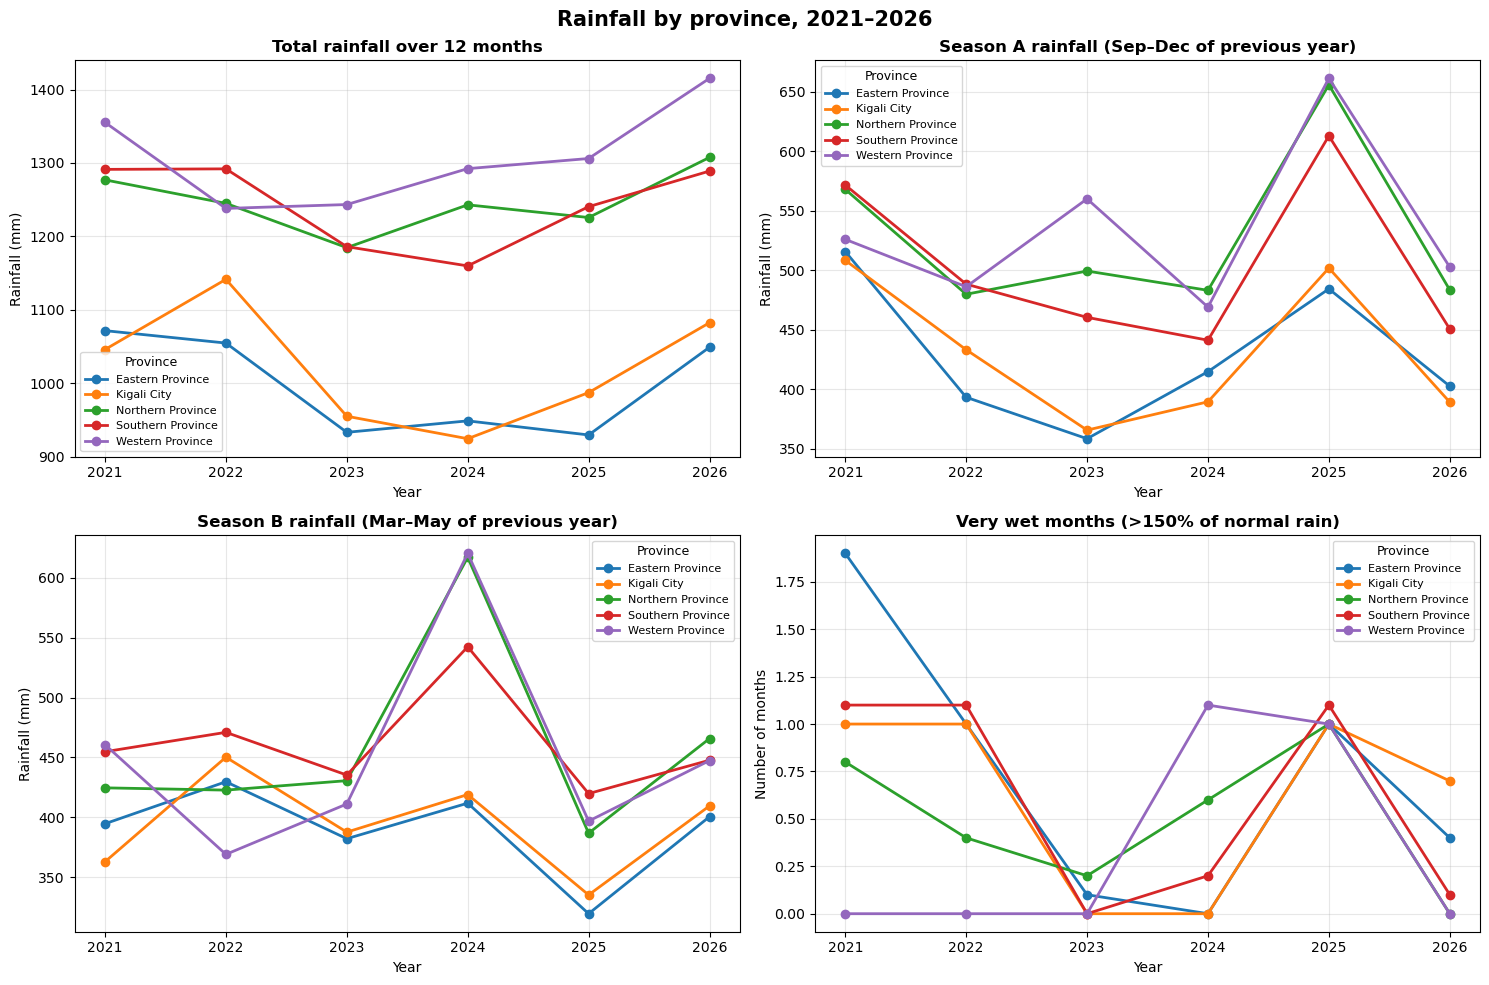

In [49]:
# Key rain indicators per province, 2021-2026 (province value = average of its districts)
INDICATORS = {
    "rain_12m_mm": ("Total rainfall over 12 months", "Rainfall (mm)"),
    "rain_seasonA_mm": ("Season A rainfall (Sep–Dec of previous year)", "Rainfall (mm)"),
    "rain_seasonB_mm": ("Season B rainfall (Mar–May of previous year)", "Rainfall (mm)"),
    "rain_n_wet_months": ("Very wet months (>150% of normal rain)", "Number of months"),
}
YEARS = sorted(rain_prov["year"].unique())

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (col, (title, ylabel)) in zip(axes.ravel(), INDICATORS.items()):
    for province, g in rain_prov.groupby("province"):
        ax.plot(g["year"], g[col], marker="o", linewidth=2, label=province)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.set_xticks(YEARS)                      # one tick per year: 2021, 2022, ... 2026
    ax.set_xticklabels([str(y) for y in YEARS])
    ax.grid(alpha=0.3)
    ax.legend(title="Province", fontsize=8, title_fontsize=9, loc="best", framealpha=0.8)

fig.suptitle("Rainfall by province, 2021–2026", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


District rain progress over last 5 years

In [50]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("food_security_dataset.csv")
recent = df[df["year"].between(2021, 2026)]

INDICATOR = "rain_12m_pct_normal"   # change to any rain_ column

for province, g in recent.groupby("province"):
    print(f"\n=== {province} — {INDICATOR} ===")
    display(g.pivot(index="district", columns="year", values=INDICATOR).round(1))



=== Eastern Province — rain_12m_pct_normal ===


year,2021,2022,2023,2024,2025,2026
district,,,,,,
Bugesera,104.8,108.5,93.4,95.3,99.8,108.6
Gatsibo,113.6,112.1,99.1,102.2,93.2,109.7
Kayonza,118.9,111.7,102.4,100.1,93.1,112.7
Kirehe,112.3,111.2,100.0,98.3,100.4,108.9
Ngoma,108.4,108.0,94.0,93.7,97.4,108.5
Nyagatare,113.3,107.0,97.2,107.2,96.5,104.3
Rwamagana,108.3,108.6,92.8,93.8,96.0,110.4



=== Kigali City — rain_12m_pct_normal ===


year,2021,2022,2023,2024,2025,2026
district,,,,,,
Gasabo,105.0,114.1,94.1,93.9,98.1,108.0
Kicukiro,104.0,112.9,94.0,91.1,98.0,107.3
Nyarugenge,102.2,112.7,96.0,89.9,97.6,106.7



=== Northern Province — rain_12m_pct_normal ===


year,2021,2022,2023,2024,2025,2026
district,,,,,,
Burera,108.0,101.3,103.6,104.6,103.9,109.8
Gakenke,109.8,106.4,102.7,106.3,107.3,112.8
Gicumbi,106.4,108.8,96.0,101.2,96.8,106.6
Musanze,108.7,97.7,100.6,109.6,108.1,113.2
Rulindo,105.2,112.5,96.3,101.3,99.4,108.3



=== Southern Province — rain_12m_pct_normal ===


year,2021,2022,2023,2024,2025,2026
district,,,,,,
Gisagara,113.6,117.2,107.1,100.9,112.6,110.6
Huye,113.2,116.6,106.1,97.9,111.3,111.7
Kamonyi,105.6,113.0,99.1,96.4,99.5,106.4
Muhanga,110.7,108.7,99.4,103.0,105.2,110.1
Nyamagabe,107.7,100.4,96.8,99.9,103.6,111.6
Nyanza,113.3,118.4,102.4,100.3,107.5,110.4
Nyaruguru,110.2,103.3,101.6,97.5,106.8,112.5
Ruhango,111.2,112.2,100.8,99.4,102.8,109.0



=== Western Province — rain_12m_pct_normal ===


year,2021,2022,2023,2024,2025,2026
district,,,,,,
Karongi,105.4,96.4,94.7,97.5,99.5,106.5
Ngororero,108.7,98.5,95.1,103.3,105.7,108.8
Nyabihu,107.2,97.3,98.0,110.0,108.0,113.1
Nyamasheke,104.4,94.0,99.7,97.3,99.7,111.1
Rubavu,102.1,96.1,96.1,102.0,101.2,111.7
Rusizi,105.5,95.6,99.4,96.0,97.5,110.8
Rutsiro,104.9,97.0,93.2,98.6,100.5,108.3


In [51]:
rain_cols = ["rain_12m_mm", "rain_12m_pct_normal", "rain_seasonA_pct_normal",
             "rain_seasonB_pct_normal", "rain_n_dry_months", "rain_n_wet_months"]

(recent[recent["province"] == "Kigali City"]
     .set_index(["district", "year"])[rain_cols]
     .sort_index()
     .round(1))


rain_12m_mm  rain_12m_pct_normal  rain_seasonA_pct_normal  \
district   year                                                              
Gasabo     2021       1065.5                105.0                    125.0   
           2022       1158.0                114.1                    109.5   
           2023        955.2                 94.1                     90.1   
           2024        953.7                 93.9                    100.5   
           2025        995.7                 98.1                    125.8   
           2026       1096.7                108.0                     97.2   
Kicukiro   2021       1021.1                104.0                    127.5   
           2022       1108.4                112.9                    105.4   
           2023        923.3                 94.0                     90.1   
           2024        894.9                 91.1                     97.8   
           2025        962.8                 98.0                    126.2   
           2026       1054.1                107.3                     97.0   
Nyarugenge 2021       1051.0                102.2                    126.8   
           2022       1158.0                112.7                    108.1   
           2023        986.5                 96.0                     92.6   
           2024        924.5                 89.9                     92.3   
           2025       1003.0                 97.6                    122.4   
           2026       1096.5                106.7                     96.2   

                 rain_seasonB_pct_normal  rain_n_dry_months  rain_n_wet_months  
district   year                                                                 
Gasabo     2021                     93.0                  1                  1  
           2022                    114.3                  0                  1  
           2023                     96.7                  0                  0  
           2024                    109.7                  0                  0  
           2025                     83.9                  2                  1  
           2026                    105.8                  2                  1  
Kicukiro   2021                     94.3                  1                  1  
           2022                    117.6                  0                  1  
           2023                     98.3                  0                  0  
           2024                    103.4                  0                  0  
           2025                     83.9                  2                  1  
           2026                    105.4                  2                  1  
Nyarugenge 2021                     89.6                  1                  1  
           2022                    111.9                  0                  1  
           2023                    100.8                  1                  0  
           2024                    106.6                  0                  0  
           2025                     87.9                  2                  1  
           2026                    101.3                  1                  0

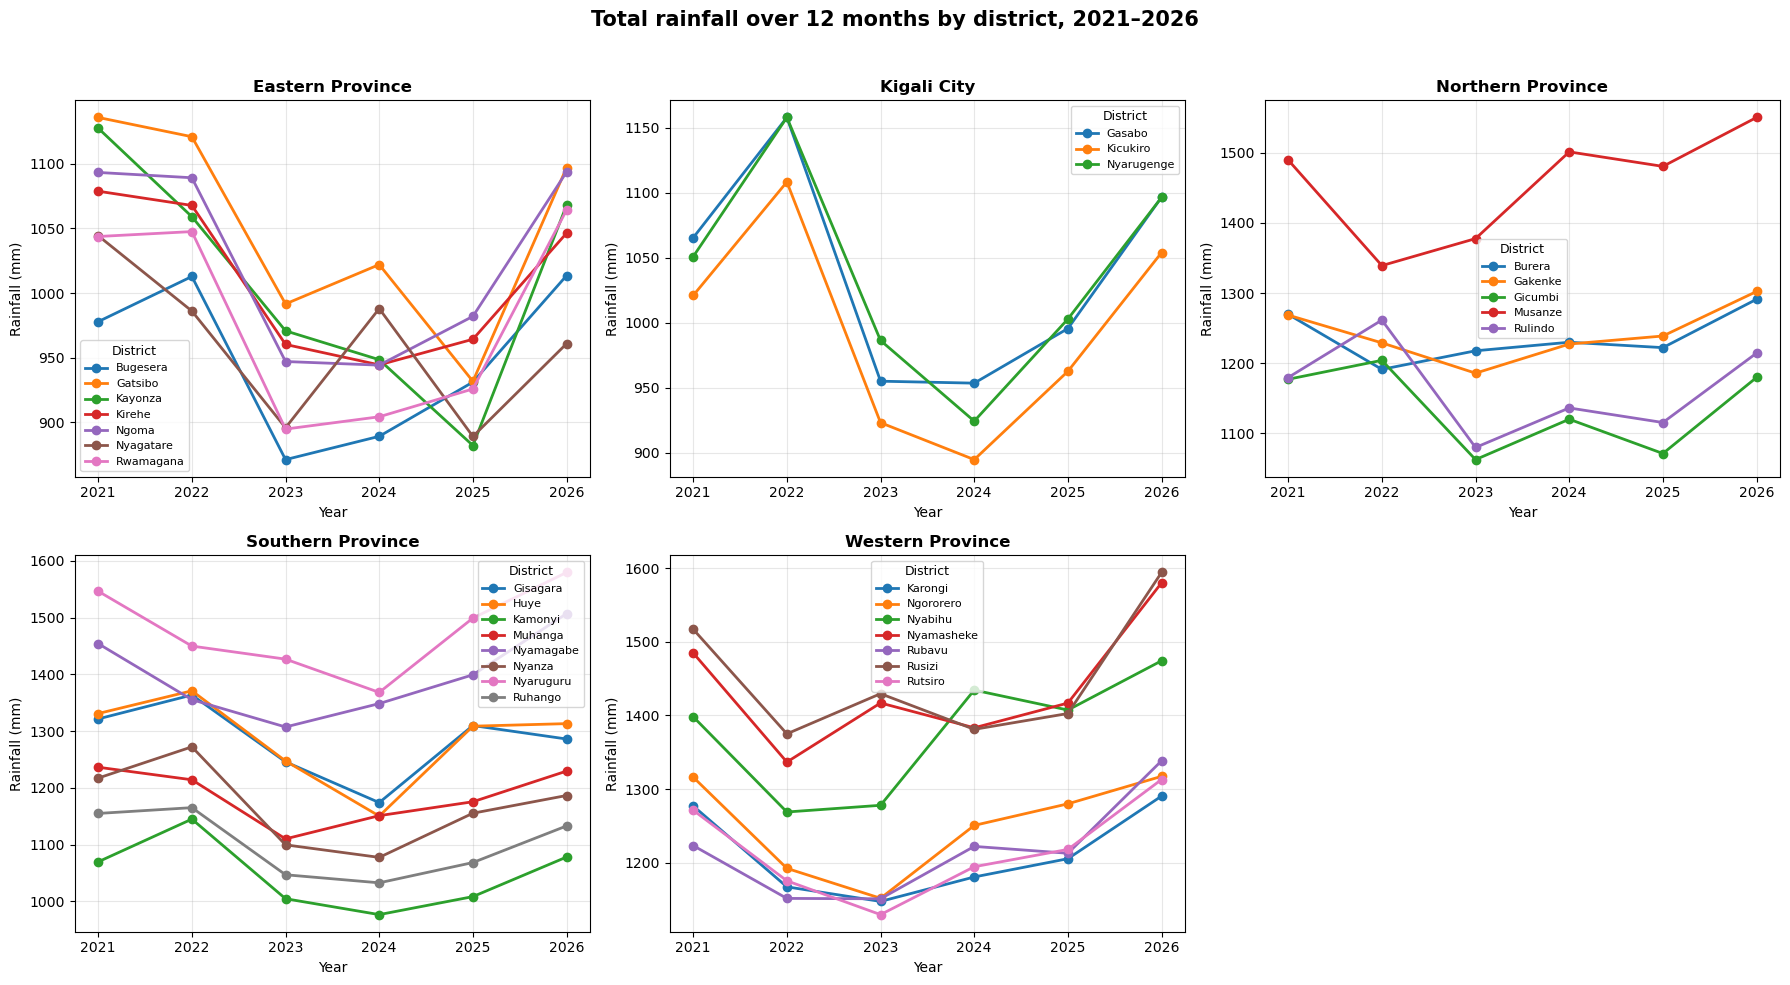

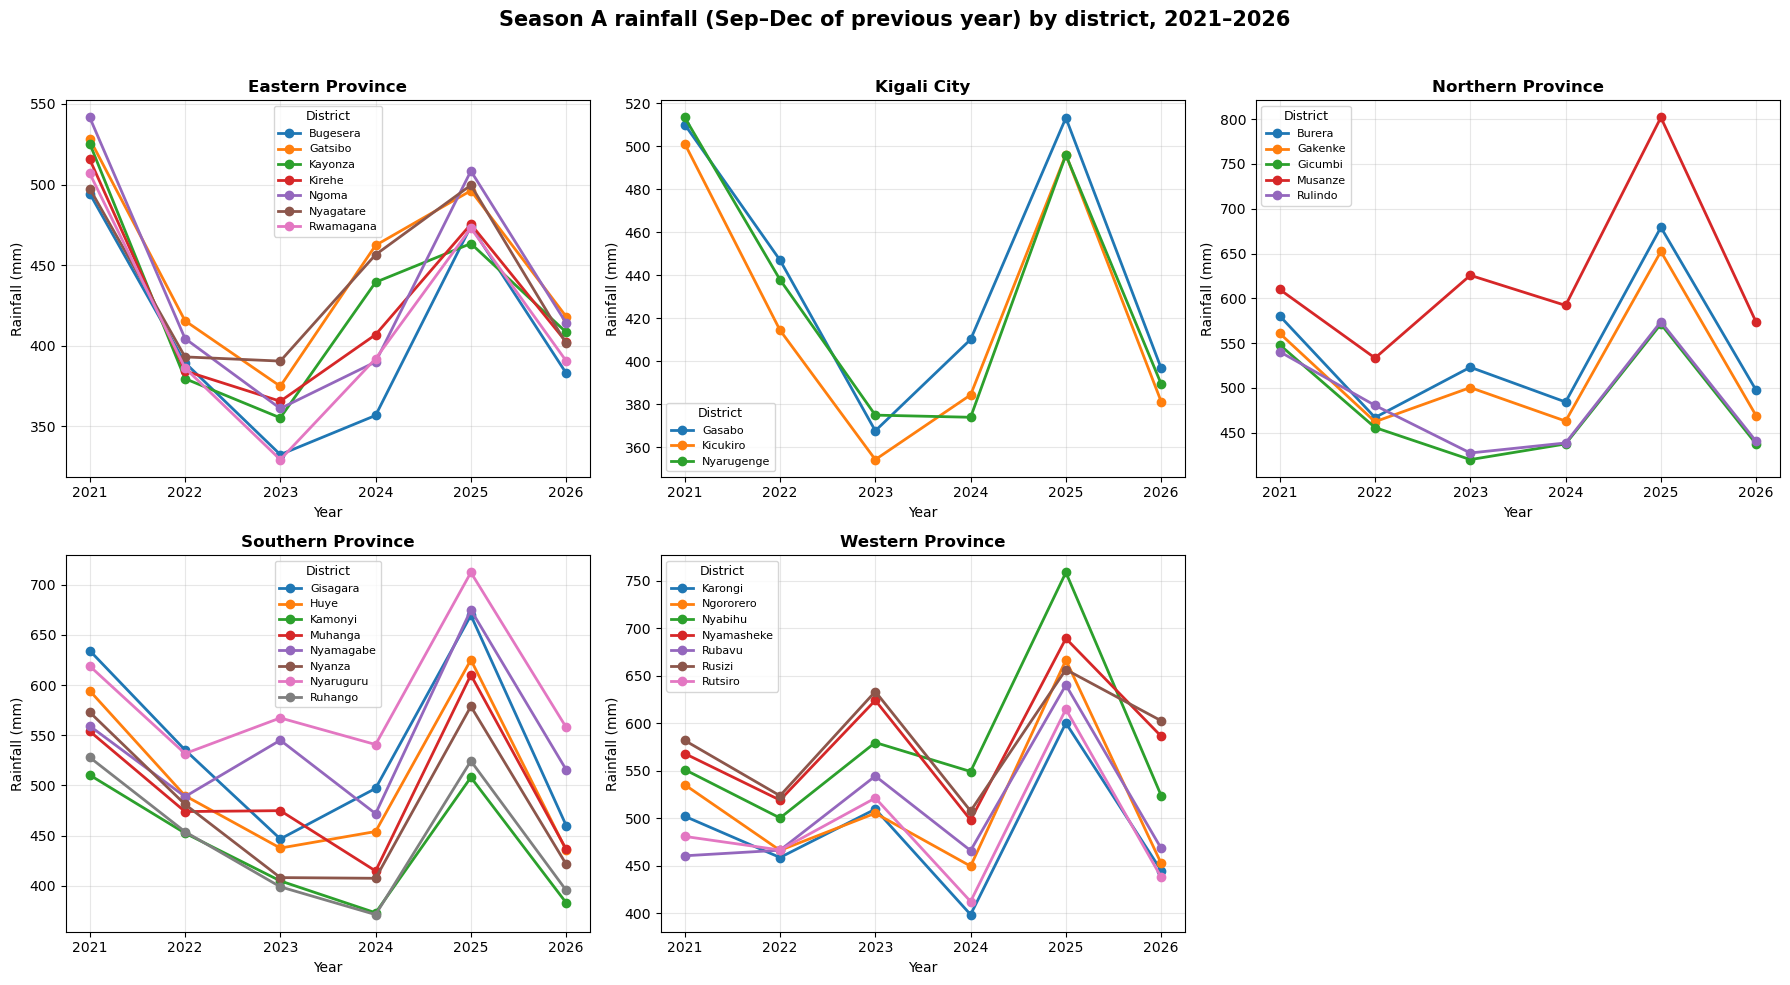

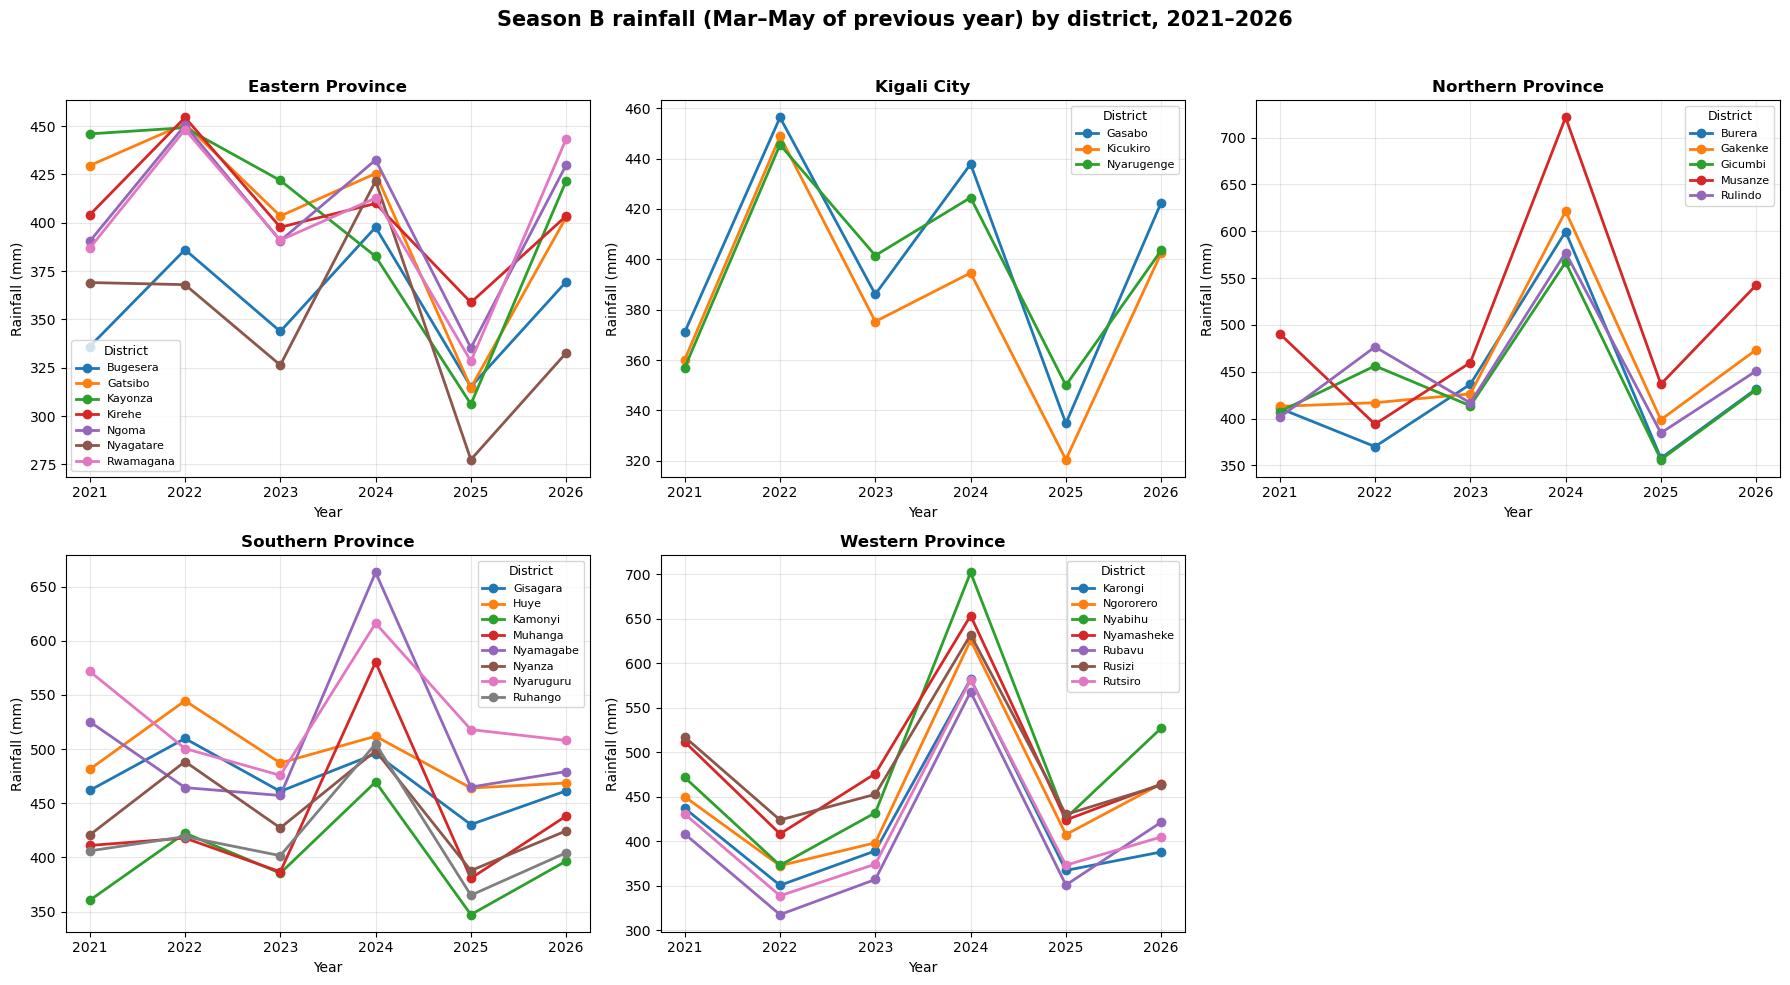

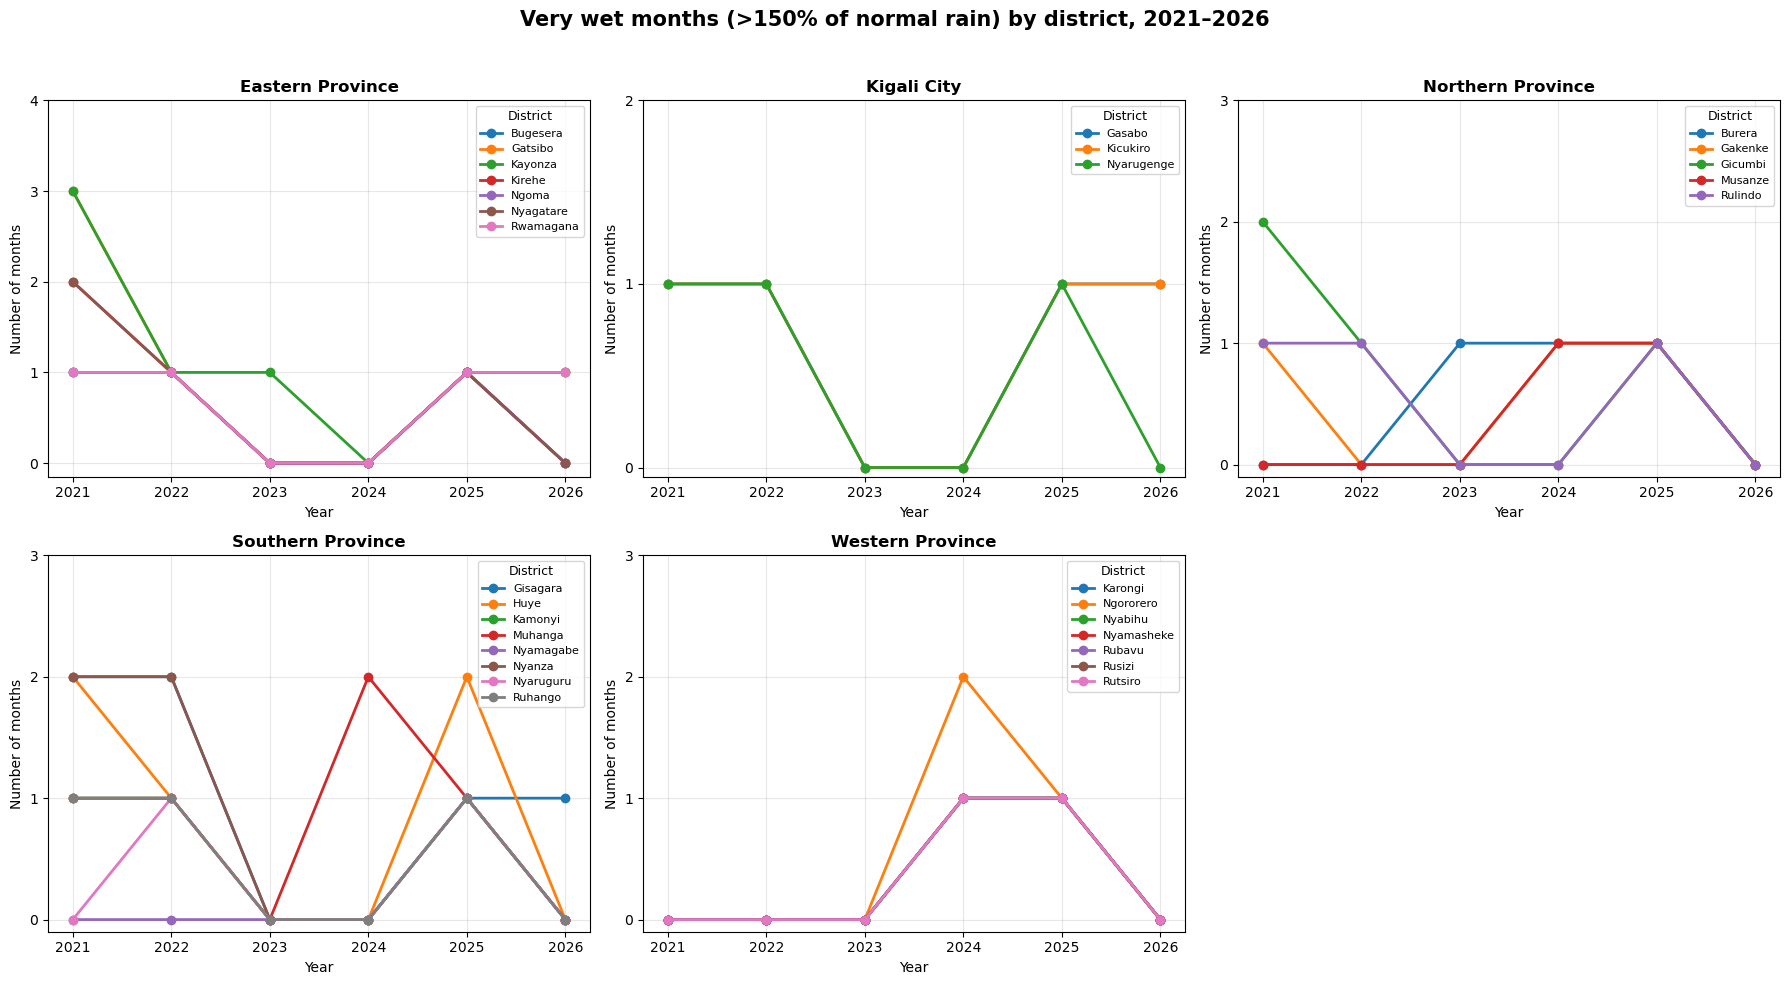

In [52]:
# Key rain indicators for every district, grouped by province, 2021-2026
# One figure per indicator; one panel per province (max 3 per row); one line per district
import math

INDICATORS = {
    "rain_12m_mm": ("Total rainfall over 12 months", "Rainfall (mm)"),
    "rain_seasonA_mm": ("Season A rainfall (Sep–Dec of previous year)", "Rainfall (mm)"),
    "rain_seasonB_mm": ("Season B rainfall (Mar–May of previous year)", "Rainfall (mm)"),
    "rain_n_wet_months": ("Very wet months (>150% of normal rain)", "Number of months"),
}
provinces = sorted(recent["province"].unique())
YEARS = sorted(recent["year"].unique())
N_COLS = 3
n_rows = math.ceil(len(provinces) / N_COLS)

for col, (title, ylabel) in INDICATORS.items():
    fig, axes = plt.subplots(n_rows, N_COLS, figsize=(18, 5 * n_rows))
    axes = axes.ravel()
    for ax, province in zip(axes, provinces):
        g = recent[recent["province"] == province]
        for district, d in g.groupby("district"):
            ax.plot(d["year"], d[col], marker="o", linewidth=2, label=district)
        ax.set_title(province, fontsize=12, fontweight="bold")
        ax.set_xlabel("Year")
        ax.set_ylabel(ylabel)
        ax.set_xticks(YEARS)                      # one tick per year: 2021, 2022, ... 2026
        ax.set_xticklabels([str(y) for y in YEARS])
        if col == "rain_n_wet_months":
            ax.set_yticks(range(0, int(g[col].max()) + 2))   # whole months only
        ax.grid(alpha=0.3)
        ax.legend(title="District", fontsize=8, title_fontsize=9, loc="best", framealpha=0.8)
    for ax in axes[len(provinces):]:             # hide empty panels
        ax.set_visible(False)
    fig.suptitle(f"{title} by district, 2021–2026", fontsize=15, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


In [53]:
df[df["food_insecure_pct"].isna()]


,year,province,district,district_pcode,food_insecure_pct,risk_class,label_source,is_survey_year,last_survey_food_insecure_pct,rain_12m_mm,...,sas_inorganic_fert_plots_pct,sas_inorganic_kg_ha,sas_dap_kg_ha,sas_urea_kg_ha,sas_npk_kg_ha,sas_n_seasons,sas_maize_yield_change_pct,sas_beans_yield_change_pct,sas_cassava_yield_change_pct,sas_irish_potato_yield_change_pct
570,2025,Kigali City,Nyarugenge,RW11,NaN,NaN,forecast_no_target,False,5.99,1003.0,...,6.53,6.15,1.46,3.99,0.59,2.0,-14.18,44.27,-70.40,70.00
571,2025,Kigali City,Gasabo,RW12,NaN,NaN,forecast_no_target,False,4.48,995.7,...,25.65,43.86,13.80,17.71,12.23,3.0,-18.53,1.51,-54.63,45.40
572,2025,Kigali City,Kicukiro,RW13,NaN,NaN,forecast_no_target,False,1.75,962.8,...,21.74,28.83,14.45,9.61,4.75,3.0,-14.08,4.89,-71.54,NaN
573,2025,Southern Province,Nyanza,RW21,NaN,NaN,forecast_no_target,False,20.31,1155.3,...,15.28,18.00,5.70,7.19,4.97,3.0,-9.02,18.24,-39.13,-1.52
574,2025,Southern Province,Gisagara,RW22,NaN,NaN,forecast_no_target,False,25.37,1309.7,...,25.22,40.08,11.66,12.89,11.78,3.0,-16.57,23.12,-42.74,5.65
575,2025,Southern Province,Nyaruguru,RW23,NaN,NaN,forecast_no_target,False,21.21,1499.0,...,39.17,123.90,47.29,23.07,35.50,3.0,17.72,20.18,-32.40,9.75
576,2025,Southern Province,Huye,RW24,NaN,NaN,forecast_no_target,False,21.42,1308.6,...,20.81,125.92,47.83,65.80,11.28,3.0,1.69,31.82,-20.17,12.51
577,2025,Southern Province,Nyamagabe,RW25,NaN,NaN,forecast_no_target,False,34.51,1399.1,...,36.47,133.32,31.61,17.45,21.77,3.0,12.70,-0.75,32.07,13.01
578,2025,Southern Province,Ruhango,RW26,NaN,NaN,forecast_no_target,False,28.30,1068.4,...,11.56,14.78,3.66,5.82,3.26,3.0,-4.48,26.48,14.08,-38.71
579,2025,Southern Province,Muhanga,RW27,NaN,NaN,forecast_no_target,False,24.48,1175.5,...,15.96,18.04,8.81,4.68,4.22,3.0,-1.94,20.30,25.55,-29.22


In [54]:
# features
year = ["year"]
categorical = ["province", "district"]
climate_numerical_values = ["last_survey_food_insecure_pct",
                    "rain_12m_mm", "rain_n_dry_months",
                    "rain_n_wet_months", "rain_seasonB_mm", "rain_seasonA_mm",
                    "temp_12m_c", "temp_max_month_c",
                    "temp_seasonB_c", "temp_seasonA_c",
                    ]
market_prices_staples = ["price_beans_rwf_kg", "price_maize_rwf_kg", "price_cassava_flour_rwf_kg",
                 "price_irish_potato_rwf_kg", "price_sorghum_rwf_kg"]

agriculture_details = [col for col in df.columns if col.startswith("sas_")]
# target
food_pct_insecure = ["food_insecure_pct"]

In [55]:
# Train on 2006-2020, test on 2021-2024 (rows with a target)
TARGET = "food_insecure_pct"   # a string, so y is a 1-D Series

# One value is infinite (Rubavu 2021 cassava yield change: previous yield was 0); treat it as missing
model_df = df.replace([np.inf, -np.inf], np.nan)

train_df = model_df[model_df["year"] < 2021]
test_df = model_df[model_df["year"].between(2021, 2024)]

# SAS columns that are completely empty in the training years carry no information: leave them out
empty_in_train = [c for c in agriculture_details if train_df[c].isna().all()]
agriculture_used = [c for c in agriculture_details if c not in empty_in_train + ["sas_n_seasons"]]
print("Left out (empty before 2021):", empty_in_train + ["sas_n_seasons"])

all_features = year + categorical + climate_numerical_values + agriculture_used + market_prices_staples

X_train, y_train = train_df[all_features], train_df[TARGET]
X_train.to_csv("train.csv")

Left out (empty before 2021): ['sas_maize_production_t', 'sas_beans_production_t', 'sas_cassava_production_t', 'sas_irish_potato_production_t', 'sas_sweet_potato_production_t', 'sas_sorghum_production_t', 'sas_banana_production_t', 'sas_rice_production_t', 'sas_worse_harvest_pct', 'sas_n_seasons']


In [56]:
# Test set: the same feature columns as training, plus the target
X_test, y_test = test_df[all_features], test_df[TARGET]
X_test.to_csv("test.csv")
print("train:", X_train.shape, "| test:", X_test.shape)

train: (450, 45) | test: (120, 45)


In [57]:
numeric = year + climate_numerical_values + agriculture_used + market_prices_staples

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])
rf_model = Pipeline([
    ("preprocess", preprocess),
    ("regressor", RandomForestRegressor(
        n_estimators=500,
        criterion="absolute_error",
        max_depth=7,
        min_samples_split=2,
        min_samples_leaf=2,
        max_features="sqrt",
        bootstrap=True,
        random_state=RANDOM_STATE,
        verbose=0,
        n_jobs=2
    ))
])
rf_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If t

In [58]:
def regression_scores(y_true, y_pred):
    """MAE, RMSE (percentage points) and R² for food insecurity predictions."""
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

In [59]:
# Fit on the training features, then predict from FEATURES (X), never from the target (y)
rf_model.fit(X_train, y_train)

pred_train = rf_model.predict(X_train)
pred_test = rf_model.predict(X_test)

In [60]:
# Errors on train and test. 2021 and 2024 are real surveys; 2022-2023 are interpolated between them.
survey = (test_df["label_source"] == "cari_survey").values

results = pd.DataFrame({
    "train (2006-2020)": regression_scores(y_train, pred_train),
    "test (2021-2024, all rows)": regression_scores(y_test, pred_test),
    "test (2021 + 2024 surveys only)": regression_scores(y_test[survey], pred_test[survey]),
    "persistence (surveys only)": regression_scores(
        y_test[survey], test_df.loc[survey, "last_survey_food_insecure_pct"]),
}).round(3)
results

,train (2006-2020),"test (2021-2024, all rows)",test (2021 + 2024 surveys only),persistence (surveys only)
MAE,3.49,4.529,5.387,7.323
RMSE,4.61,5.732,6.768,9.285
R2,0.81,0.700,0.617,0.280


In [61]:
# Mean absolute error per test year (percentage points)
per_year = (test_df.assign(abs_error=(y_test - pred_test).abs())
                   .groupby("year")["abs_error"].mean().round(2))
per_year

year
2021    6.33
2022    3.80
2023    3.55
2024    4.44
Name: abs_error, dtype: float64

## CatBoost regression

Same train/test split, features and scores as the random forest above. CatBoost handles missing values and the categorical columns (`province`, `district`) itself, so it needs no imputer, scaler or one-hot encoding. No early stopping is used, because the only held-out data is the test set and tuning on it would leak.

In [62]:
cb_model = CatBoostRegressor(
    loss_function="RMSE",
    iterations=500,
    learning_rate=0.03,
    depth=4,
    l2_leaf_reg=10,
    random_seed=RANDOM_STATE,
    verbose=0,
)

# Fit on the same X_train / y_train as the random forest; province and district are passed as categories
cb_model.fit(X_train, y_train, cat_features=categorical)

cb_pred_train = cb_model.predict(X_train)
cb_pred_test = cb_model.predict(X_test)

In [63]:
# CatBoost errors on train and test (same layout as the random forest table)
survey = (test_df["label_source"] == "cari_survey").values
train_years = f"{train_df['year'].min()}-{train_df['year'].max()}"
test_years = f"{test_df['year'].min()}-{test_df['year'].max()}"
survey_years = " + ".join(str(y) for y in sorted(test_df.loc[survey, "year"].unique()))

cb_results = pd.DataFrame({
    f"train ({train_years})": regression_scores(y_train, cb_pred_train),
    f"test ({test_years}, all rows)": regression_scores(y_test, cb_pred_test),
    f"test ({survey_years} surveys only)": regression_scores(y_test[survey], cb_pred_test[survey]),
    "persistence (surveys only)": regression_scores(
        y_test[survey], test_df.loc[survey, "last_survey_food_insecure_pct"]),
}).round(3)
cb_results

,train (2006-2020),"test (2021-2024, all rows)",test (2021 + 2024 surveys only),persistence (surveys only)
MAE,2.883,4.721,5.774,7.323
RMSE,3.770,6.050,7.163,9.285
R2,0.873,0.666,0.571,0.280


In [64]:
# CatBoost mean absolute error per test year (percentage points)
cb_per_year = (test_df.assign(abs_error=(y_test - cb_pred_test).abs())
                      .groupby("year")["abs_error"].mean().round(2))
cb_per_year

year
2021    5.60
2022    3.18
2023    4.16
2024    5.95
Name: abs_error, dtype: float64

In [65]:
# Side-by-side: random forest vs CatBoost vs persistence, on the real survey rows only
comparison = pd.DataFrame({
    "random forest": regression_scores(y_test[survey], pred_test[survey]),
    "catboost": regression_scores(y_test[survey], cb_pred_test[survey]),
    "persistence": regression_scores(y_test[survey], test_df.loc[survey, "last_survey_food_insecure_pct"]),
}).round(3)
comparison

,random forest,catboost,persistence
MAE,5.387,5.774,7.323
RMSE,6.768,7.163,9.285
R2,0.617,0.571,0.280


## Random forest: predicted vs real food insecurity, 2021-2024

Each test row shows the district's real share of food-insecure households, the random forest prediction, and the difference (positive = the model predicted too high). 2021 and 2024 are real survey values; 2022 and 2023 are interpolated between them.

In [66]:
test_comparison = test_df[["year", "province", "district", "label_source"]].copy()
test_comparison["real_pct"] = y_test.round(1)
test_comparison["predicted_pct"] = pred_test.round(1)
test_comparison["error"] = (test_comparison["predicted_pct"] - test_comparison["real_pct"]).round(1)
test_comparison = test_comparison.sort_values(["year", "province", "district"]).reset_index(drop=True)

with pd.option_context("display.max_rows", None):
    display(test_comparison)

,year,province,district,label_source,real_pct,predicted_pct,error
0,2021,Eastern Province,Bugesera,cari_survey,18.3,14.6,-3.7
1,2021,Eastern Province,Gatsibo,cari_survey,26.3,14.9,-11.4
2,2021,Eastern Province,Kayonza,cari_survey,12.2,18.3,6.1
3,2021,Eastern Province,Kirehe,cari_survey,9.9,18.2,8.3
4,2021,Eastern Province,Ngoma,cari_survey,14.1,14.4,0.3
5,2021,Eastern Province,Nyagatare,cari_survey,12.1,15.9,3.8
6,2021,Eastern Province,Rwamagana,cari_survey,7.4,13.8,6.4
7,2021,Kigali City,Gasabo,cari_survey,5.3,7.3,2.0
8,2021,Kigali City,Kicukiro,cari_survey,3.6,6.1,2.5
9,2021,Kigali City,Nyarugenge,cari_survey,5.4,4.6,-0.8


In [67]:
# Same comparison, one row per district: real vs predicted for each test year side by side
side_by_side = test_comparison.pivot(index=["province", "district"], columns="year",
                                     values=["real_pct", "predicted_pct"])
side_by_side = side_by_side.swaplevel(axis=1).sort_index(axis=1, level=0)
with pd.option_context("display.max_rows", None):
    display(side_by_side)

year                                  2021                   2022           \
                             predicted_pct real_pct predicted_pct real_pct   
province          district                                                   
Eastern Province  Bugesera            14.6     18.3          17.5     17.8   
                  Gatsibo             14.9     26.3          17.3     23.0   
                  Kayonza             18.3     12.2          15.4     12.0   
                  Kirehe              18.2      9.9          15.1     11.6   
                  Ngoma               14.4     14.1          15.2     15.9   
                  Nyagatare           15.9     12.1          14.2      9.8   
                  Rwamagana           13.8      7.4          13.3     10.6   
Kigali City       Gasabo               7.3      5.3           9.1      5.0   
                  Kicukiro             6.1      3.6           6.3      3.0   
                  Nyarugenge           4.6      5.4           5.8      5.6   
Northern Province Burera              27.0     41.6          28.0     34.8   
                  Gakenke             18.0      8.2          17.7     10.8   
                  Gicumbi             19.1      6.4          18.3      9.5   
                  Musanze             18.2     14.2          19.3     13.1   
                  Rulindo             18.5     27.0          23.8     24.3   
Southern Province Gisagara            20.4     28.4          21.6     27.4   
                  Huye                18.5     23.2          22.8     22.6   
                  Kamonyi             19.4     13.1          16.9     13.2   
                  Muhanga             17.8     15.1          18.9     18.2   
                  Nyamagabe           29.2     25.5          29.1     28.5   
                  Nyanza              20.8     28.5          22.5     25.8   
                  Nyaruguru           26.8     28.9          27.9     26.3   
                  Ruhango             18.5     16.6          18.7     20.5   
Western Province  Karongi             30.0     41.2          31.7     35.4   
                  Ngororero           33.4     52.5          33.4     44.9   
                  Nyabihu             27.6     23.5          28.0     21.3   
                  Nyamasheke          28.7     32.6          29.8     34.4   
                  Rubavu              28.0     29.7          28.3     29.5   
                  Rusizi              27.7     19.3          26.1     18.6   
                  Rutsiro             39.2     48.9          38.3     41.5   

year                                  2023                   2024           
                             predicted_pct real_pct predicted_pct real_pct  
province          district                                                  
Eastern Province  Bugesera            16.8     17.3          16.9     16.9  
                  Gatsibo             16.8     19.6          17.9     16.3  
                  Kayonza             14.2     11.8          14.5     11.6  
                  Kirehe              13.6     13.2          14.7     14.8  
                  Ngoma               13.4     17.7          14.7     19.5  
                  Nyagatare           13.3      7.5          14.4      5.2  
                  Rwamagana           12.1     13.8          12.4     17.0  
Kigali City       Gasabo               7.9      4.8           7.0      4.5  
                  Kicukiro             5.1      2.4           5.0      1.8  
                  Nyarugenge           4.5      5.8           4.6      6.0  
Northern Province Burera              27.4     28.1          26.0     21.3  
                  Gakenke             18.6     13.3          16.9     15.9  
                  Gicumbi             17.2     12.5          15.9     15.6  
                  Musanze             18.5     12.0          18.7     10.9  
                  Rulindo             23.1     21.6          20.9     18.9  
Southern Province Gisagara            2

## Random forest forecast, 2025-2026

There is no survey yet for 2025 and 2026, so there is no real value to compare with: these are forecasts. They use the 2025-2026 feature rows of the dataset (rainfall, temperature, prices, SAS and each district's 2024 survey value).

The forecast model has the **same settings as the random forest above**, but is retrained on **all labelled years (2006-2024)**, so it also learns from the 2021 and 2024 surveys. Note that 2026 SAS features are incomplete: Season A 2026 is not published yet.

In [68]:
from sklearn.base import clone

labelled = model_df[model_df["year"] <= 2024]
forecast_rows = model_df[model_df["year"].between(2025, 2026)]

# Same random forest settings, retrained on every year with a target
final_rf = clone(rf_model).fit(labelled[all_features], labelled[TARGET])

forecast = forecast_rows[["year", "province", "district", "last_survey_food_insecure_pct"]].copy()
forecast = forecast.rename(columns={"last_survey_food_insecure_pct": "real_pct_2024_survey"})
forecast["predicted_pct"] = final_rf.predict(forecast_rows[all_features]).round(1)
forecast["predicted_risk"] = pd.cut(forecast["predicted_pct"], [-np.inf, 15, 30, np.inf],
                                    right=False, labels=["low", "medium", "high"])
forecast = forecast.sort_values(["year", "province", "district"]).reset_index(drop=True)

with pd.option_context("display.max_rows", None):
    display(forecast)

,year,province,district,real_pct_2024_survey,predicted_pct,predicted_risk
0,2025,Eastern Province,Bugesera,16.87,16.0,medium
1,2025,Eastern Province,Gatsibo,16.26,14.6,low
2,2025,Eastern Province,Kayonza,11.57,14.0,low
3,2025,Eastern Province,Kirehe,14.76,14.0,low
4,2025,Eastern Province,Ngoma,19.48,16.2,medium
5,2025,Eastern Province,Nyagatare,5.24,12.4,low
6,2025,Eastern Province,Rwamagana,17.00,15.3,medium
7,2025,Kigali City,Gasabo,4.48,7.3,low
8,2025,Kigali City,Kicukiro,1.75,4.5,low
9,2025,Kigali City,Nyarugenge,5.99,5.2,low


In [69]:
# Forecast side by side: one row per district, 2024 survey value next to the 2025 and 2026 forecasts
forecast_wide = forecast.pivot(index=["province", "district", "real_pct_2024_survey"], columns="year",
                               values="predicted_pct").add_prefix("predicted_").reset_index()
with pd.option_context("display.max_rows", None):
    display(forecast_wide)

year,province,district,real_pct_2024_survey,predicted_2025,predicted_2026
0,Eastern Province,Bugesera,16.87,16.0,15.9
1,Eastern Province,Gatsibo,16.26,14.6,15.1
2,Eastern Province,Kayonza,11.57,14.0,13.8
3,Eastern Province,Kirehe,14.76,14.0,14.4
4,Eastern Province,Ngoma,19.48,16.2,16.2
5,Eastern Province,Nyagatare,5.24,12.4,12.1
6,Eastern Province,Rwamagana,17.00,15.3,14.4
7,Kigali City,Gasabo,4.48,7.3,6.2
8,Kigali City,Kicukiro,1.75,4.5,3.8
9,Kigali City,Nyarugenge,5.99,5.2,5.1


In [70]:
from sklearn.metrics import confusion_matrix, accuracy_score

def to_class(s):
    return pd.cut(s, [-np.inf, 15, 30, np.inf], right=False, labels=["low", "medium", "high"]).astype(str)

t = test_comparison.assign(real_class=to_class(test_comparison["real_pct"]),
                           pred_class=to_class(test_comparison["predicted_pct"]),
                           abs_error=test_comparison["error"].abs())
s = t[t["label_source"] == "cari_survey"]          # real survey years only

print("class accuracy (2021 + 2024 surveys):", round(accuracy_score(s["real_class"], s["pred_class"]), 3))
display(pd.DataFrame(confusion_matrix(s["real_class"], s["pred_class"], labels=["low", "medium", "high"]),
                     index=["real low", "real medium", "real high"],
                     columns=["pred low", "pred medium", "pred high"]))

print("errors by size:", pd.cut(s["abs_error"], [0, 5, 10, 100]).value_counts().sort_index().to_dict())
display(s.sort_values("abs_error", ascending=False).head(8)
         [["year", "district", "real_pct", "predicted_pct", "error", "real_class", "pred_class"]])


class accuracy (2021 + 2024 surveys): 0.683


,pred low,pred medium,pred high
real low,11,9,0
real medium,4,27,2
real high,0,4,3


errors by size: {Interval(0, 5, closed='right'): 33, Interval(5, 10, closed='right'): 17, Interval(10, 100, closed='right'): 9}


,year,district,real_pct,predicted_pct,error,real_class,pred_class
24,2021,Ngororero,52.5,33.4,-19.1,high,high
10,2021,Burera,41.6,27.0,-14.6,high,medium
12,2021,Gicumbi,6.4,19.1,12.7,low,medium
1,2021,Gatsibo,26.3,14.9,-11.4,medium,low
23,2021,Karongi,41.2,30.0,-11.2,high,high
112,2024,Ruhango,28.3,17.5,-10.8,medium,medium
116,2024,Nyamasheke,38.1,27.3,-10.8,high,medium
115,2024,Nyabihu,17.0,27.6,10.6,medium,medium
